# JobAI: EDA on the ML-ready fraud dataset (v2)
Checkpoint 2. Target: `fraudulent` (1 = fake posting). Dataset built by `src/data/build_dataset.py`.

In [1]:
# setup
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import mutual_info_classif

DATA = "../data/processed/v2"
RAW = "../data/raw"
FIG = "../reports/figures/v2"

# one color per class, used on every chart
REAL, FRAUD, SYN, GRAY = "#2a78d6", "#eb6834", "#6250d6", "#9a998f"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
def save(name):
    plt.savefig(f"{FIG}/{name}", facecolor="white"); plt.show()

# load all three splits into one frame (split column kept)
df = pd.concat([pd.read_csv(f"{DATA}/{s}.csv").assign(split=s) for s in ("train", "val", "test")],
               ignore_index=True)
df["label"] = df["fraudulent"].map({0: "real", 1: "fraud"})
ds1 = df[df["source"] == "ds1_labeled"]          # the part with real labels for both classes
build_log = json.load(open(f"{DATA}/build_log.json"))
print(f"{len(df):,} postings x {df.shape[1]} columns")

# metadata: type, % missing and an example value for every column
meta = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing_%": (df.isna().mean() * 100).round(1),
                     "unique": df.nunique(),
                     "example": [str(df[c].dropna().iloc[0])[:40] for c in df.columns]})
meta

20,288 postings x 22 columns


,dtype,missing_%,unique,example
posting_id,str,0.0,20288,p000001
source,str,0.0,3,ds1_labeled
label_source,str,0.0,2,labeled
fraudulent,int64,0.0,2,1
title,str,0.0,14564,Cruise Staff Wanted *URGENT*
description,str,0.0,19648,6* Ultra Luxury American Cruise Company
employment_type,str,0.0,7,unknown
has_company,int64,0.0,2,0
has_location,int64,0.0,2,1
has_salary,int64,0.0,2,0


## 1. Lineage: how the dataset was built

In [2]:
# rows kept at each step, per source (from the build log)
steps = pd.DataFrame({k: build_log[k] for k in ("ds1_labeled", "linkedin", "techmap")}).T
steps["used_in_v2"] = [int((df.source == s).sum()) for s in steps.index]
steps

,raw,short_dropped,dupes_dropped,kept,used_in_v2
ds1_labeled,17880,17,2075,15788,15788
linkedin,20000,14,914,19072,3000
techmap,33064,24,6678,26362,1500


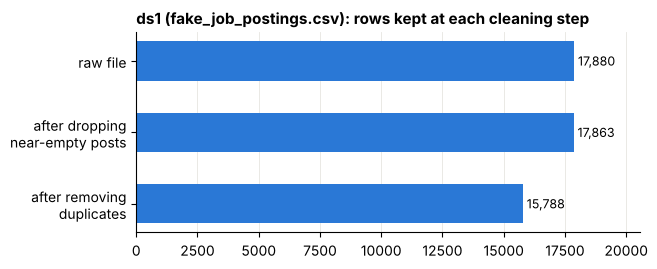

In [3]:
# funnel chart for the labeled source
lab = build_log["ds1_labeled"]
stages = ["raw file", "after dropping\nnear-empty posts", "after removing\nduplicates"]
vals = [lab["raw"], lab["raw"] - lab["short_dropped"], lab["kept"]]
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.barh(stages[::-1], vals[::-1], color=REAL, height=0.55)
for i, v in enumerate(vals[::-1]):
    ax.text(v + 150, i, f"{v:,}", va="center", fontsize=9)
ax.set_xlim(0, max(vals) * 1.15); ax.grid(axis="y", visible=False)
ax.set_title("ds1 (fake_job_postings.csv): rows kept at each cleaning step")
save("v2_lineage_ds1.png")

## 2. Class balance and sources

In [4]:
# rows and fraud rate per split
bal = df.groupby("split").agg(rows=("fraudulent", "size"), fraud=("fraudulent", "sum"))
bal["fraud_%"] = (bal.fraud / bal.rows * 100).round(2)
bal.loc[["train", "val", "test"]]

,rows,fraud,fraud_%
split,,,
train,14492,487,3.36
val,2898,97,3.35
test,2898,97,3.35


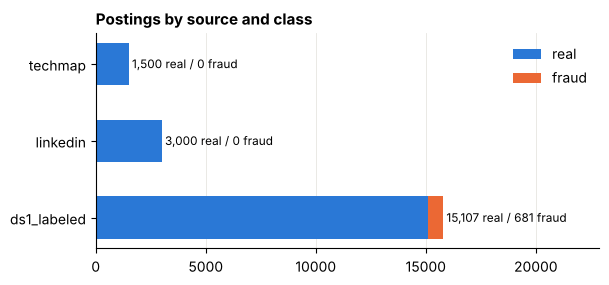

overall fraud rate: 3.4%


In [5]:
# where each class comes from
src = pd.crosstab(df.source, df.label)[["real", "fraud"]]
fig, ax = plt.subplots(figsize=(6.5, 2.8))
left = np.zeros(len(src))
for col, color in (("real", REAL), ("fraud", FRAUD)):
    ax.barh(src.index, src[col], left=left, color=color, height=0.55, label=col)
    left += src[col].values
for i, (r, f) in enumerate(src.values):
    ax.text(r + f + 150, i, f"{r:,} real / {f:,} fraud", va="center", fontsize=8.5)
ax.set_xlim(0, src.values.sum(axis=1).max() * 1.45); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper right"); ax.set_title("Postings by source and class")
save("v2_source_by_class.png")
print(f"overall fraud rate: {df.fraudulent.mean():.1%}")

## 3. Missing fields by class (feature vs target)

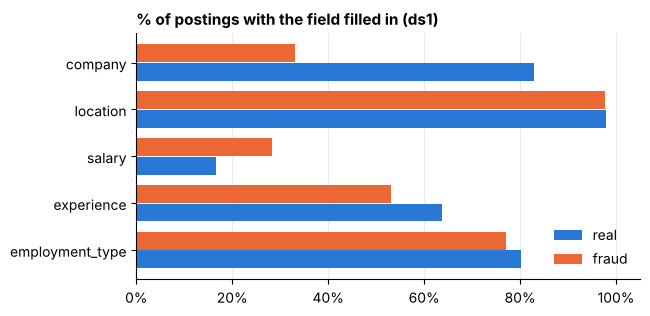

label,real,fraud
has_company,82.9,33.0
has_location,97.9,97.8
has_salary,16.5,28.2
has_experience,63.7,53.2
has_employment_type,80.1,77.1


In [6]:
# share of postings with each field filled in, real vs fraud (ds1 only, so both classes come from the same source)
fields = ["has_company", "has_location", "has_salary", "has_experience", "has_employment_type"]
rates = ds1.groupby("label")[fields].mean().T[["real", "fraud"]] * 100
fig, ax = plt.subplots(figsize=(6.5, 3.2))
y = np.arange(len(fields))
ax.barh(y + 0.2, rates.real, height=0.38, color=REAL, label="real")
ax.barh(y - 0.2, rates.fraud, height=0.38, color=FRAUD, label="fraud")
ax.set_yticks(y, [f.replace("has_", "") for f in fields]); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, 105)
ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")
ax.set_title("% of postings with the field filled in (ds1)")
save("v2_fields_by_class.png")
rates.round(1)

## 4. Description length by class

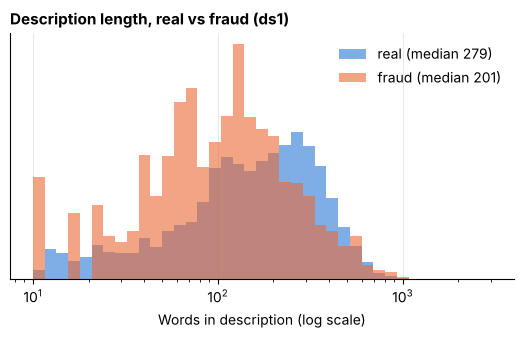

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
fraud,681.0,264.0,196.0,10.0,122.0,201.0,359.0,1347.0
real,15107.0,302.0,169.0,10.0,178.0,279.0,393.0,2115.0


In [7]:
# word count distribution, log scale because lengths are skewed (ds1 only)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
bins = np.logspace(1, np.log10(3000), 40)
for lab, color in (("real", REAL), ("fraud", FRAUD)):
    v = ds1.loc[ds1.label == lab, "desc_words"]
    ax.hist(v, bins=bins, density=True, alpha=0.6, color=color, label=f"{lab} (median {v.median():.0f})")
ax.set_xscale("log"); ax.set_yticks([]); ax.set_xlabel("Words in description (log scale)")
ax.legend(frameon=False); ax.set_title("Description length, real vs fraud (ds1)")
save("v2_desc_length_by_class.png")
ds1.groupby("label").desc_words.describe().round(0)

## 5. Text patterns by class

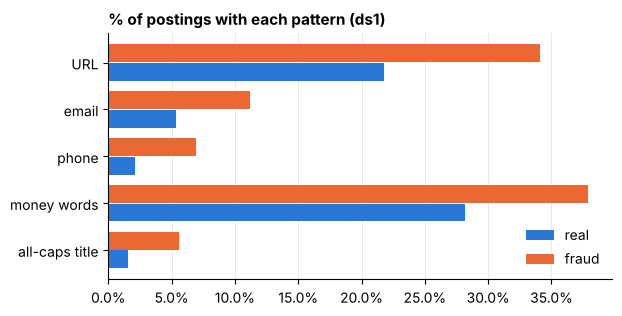

label,real,fraud,fraud / real
has_url,21.8,34.1,1.6
has_email,5.3,11.2,2.1
has_phone,2.1,6.9,3.3
money_words,28.1,37.9,1.3
title_all_caps,1.5,5.6,3.6


In [8]:
# share of postings containing a URL, email, phone, money words, or an all-caps title (ds1 only)
pats = ["has_url", "has_email", "has_phone", "money_words", "title_all_caps"]
pr = ds1.groupby("label")[pats].mean().T[["real", "fraud"]] * 100
fig, ax = plt.subplots(figsize=(6.5, 3.2))
y = np.arange(len(pats))
ax.barh(y + 0.2, pr.real, height=0.38, color=REAL, label="real")
ax.barh(y - 0.2, pr.fraud, height=0.38, color=FRAUD, label="fraud")
ax.set_yticks(y, ["URL", "email", "phone", "money words", "all-caps title"]); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right"); ax.set_title("% of postings with each pattern (ds1)")
save("v2_patterns_by_class.png")
pr["fraud / real"] = (pr.fraud / pr.real).round(1)
pr.round(1)

## 6. Employment type by class

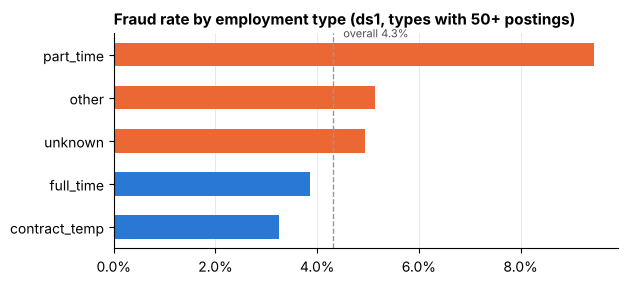

,postings,fraud_rate
employment_type,,
contract_temp,1049,3.2
full_time,10626,3.9
unknown,3157,4.9
other,214,5.1
part_time,742,9.4


In [9]:
# fraud rate within each employment type (ds1 only)
et = ds1.groupby("employment_type").agg(postings=("fraudulent", "size"), fraud_rate=("fraudulent", "mean"))
et = et[et.postings >= 50].sort_values("fraud_rate")
base = ds1.fraudulent.mean()
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh(et.index, et.fraud_rate * 100, color=[FRAUD if r > base else REAL for r in et.fraud_rate], height=0.55)
ax.axvline(base * 100, color=GRAY, ls="--", lw=1)
ax.text(base * 100 + 0.2, len(et) - 0.6, f"overall {base:.1%}", fontsize=8, color="#52514e")
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.grid(axis="y", visible=False)
ax.set_title("Fraud rate by employment type (ds1, types with 50+ postings)")
save("v2_fraud_rate_employment.png")
et.assign(fraud_rate=(et.fraud_rate * 100).round(1))

## 7. Words that separate real and fraud

In [10]:
# log-odds of each word appearing in fraud vs real descriptions (ds1, train split only, words in 20+ postings)
tr = ds1[ds1.split == "train"]
cv = CountVectorizer(stop_words="english", min_df=20, binary=True, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
X = cv.fit_transform(tr.title + " " + tr.description)
yv = tr.fraudulent.values
f_rate = (X[yv == 1].sum(0).A1 + 1) / ((yv == 1).sum() + 2)
r_rate = (X[yv == 0].sum(0).A1 + 1) / ((yv == 0).sum() + 2)
lo = pd.Series(np.log(f_rate / r_rate), index=cv.get_feature_names_out())
top = pd.DataFrame({"more common in fraud": lo.nlargest(15).index, "x": np.exp(lo.nlargest(15).values).round(1),
                    "more common in real": lo.nsmallest(15).index, "x ": np.exp(-lo.nsmallest(15).values).round(1)})
top

,more common in fraud,x,more common in real,x
0,lawson,241.6,amazing,29.1
1,darren,120.8,excited,20.8
2,distractions,69.5,touch,18.6
3,hse,51.2,gym,17.1
4,odm,47.1,keen,15.9
5,wages,24.0,custom,15.6
6,dsl,24.0,investors,15.2
7,faces,23.4,nice,14.8
8,motors,22.0,european,13.2
9,plc,20.6,stuff,13.0


## 8. Which features relate most to the target

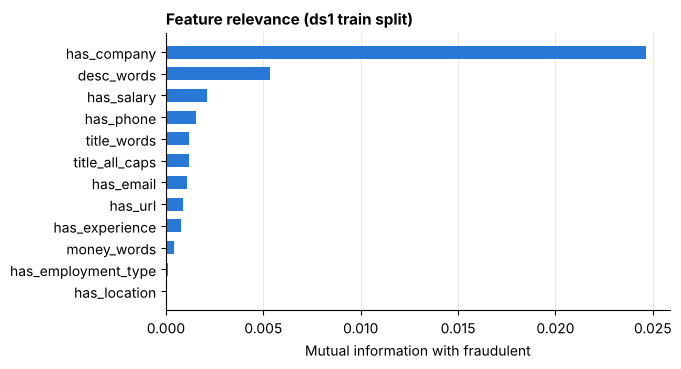

,mutual_info,correlation
has_company,0.0246,-0.256
desc_words,0.0054,-0.056
has_salary,0.0021,0.070
has_phone,0.0015,0.067
title_words,0.0012,-0.008
title_all_caps,0.0012,0.059
has_email,0.0011,0.052
has_url,0.0009,0.043
has_experience,0.0008,-0.040
money_words,0.0004,0.028


In [11]:
# mutual information between each engineered feature and the label (ds1, train split)
feats = ["has_company", "has_location", "has_salary", "has_experience", "has_employment_type",
         "has_url", "has_email", "has_phone", "money_words", "title_all_caps", "desc_words", "title_words"]
mi = pd.Series(mutual_info_classif(tr[feats], tr.fraudulent, discrete_features=[True]*10 + [False]*2,
                                   random_state=42), index=feats).sort_values()
corr = tr[feats + ["fraudulent"]].corr()["fraudulent"].drop("fraudulent")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(mi.index, mi.values, color=REAL, height=0.6)
ax.grid(axis="y", visible=False); ax.set_xlabel("Mutual information with fraudulent")
ax.set_title("Feature relevance (ds1 train split)")
save("v2_feature_relevance.png")
pd.DataFrame({"mutual_info": mi.round(4), "correlation": corr[mi.index].round(3)}).iloc[::-1]

## 9. Source check: can a model tell the sources apart?

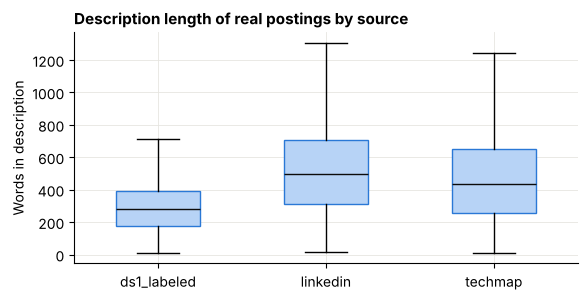

,desc_words,has_company,has_salary,has_email,money_words
source,,,,,
ds1_labeled,301.77,0.83,0.17,0.05,0.28
linkedin,532.29,0.98,0.31,0.12,0.56
techmap,484.17,1.00,0.29,0.06,0.60


In [12]:
# real postings only: if sources look very different, a model could learn "which source" instead of "fraud"
real = df[df.fraudulent == 0]
fig, ax = plt.subplots(figsize=(6.5, 3.0))
order = ["ds1_labeled", "linkedin", "techmap"]
ax.boxplot([real.loc[real.source == s, "desc_words"] for s in order], tick_labels=order, showfliers=False,
           patch_artist=True, widths=0.5, medianprops=dict(color="#0b0b0b"),
           boxprops=dict(facecolor="#b7d3f6", edgecolor=REAL))
ax.set_ylabel("Words in description"); ax.set_title("Description length of real postings by source")
save("v2_length_by_source.png")
real.groupby("source")[["desc_words", "has_company", "has_salary", "has_email", "money_words"]].mean().round(2)

## 10. Why the synthetic Fake_Postings data was removed

synthetic rows: 10,000; share with the same 'Earn $5000/week! Immediate hiring' line: 100%
synthetic description length: median 14 words (min 11, max 16)
real fraud description length (ds1): median 201 words


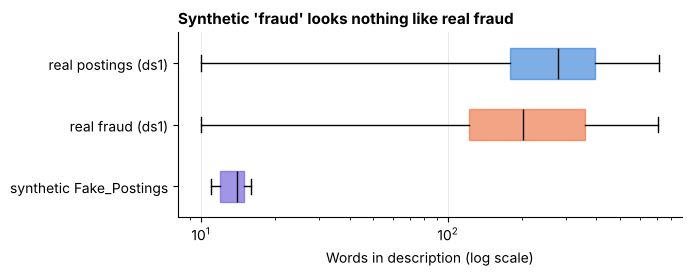

,title,description,company_profile,location
0,Mental health nurse,Arm drive court sure vote. Earn $5000/week! Im...,Rivera and Sons - Established 2022.,West Jeffrey
1,Conference centre manager,Government whom its bed go tax tree black. Ear...,"Davidson, Jones and Gomez - Established 2003.",Lake Meredithberg
2,"Engineer, land",I member discuss follow way there nation. Earn...,Allen Ltd - Established 1998.,Lake Cathybury


In [13]:
# compare the synthetic file to real fraud postings
syn = pd.read_csv(f"{RAW}/Fake_Postings.csv")
syn_words = syn.description.str.split().str.len()
template = syn.description.str.contains(r"Earn \$5000/week! Immediate hiring", regex=True).mean()
print(f"synthetic rows: {len(syn):,}; share with the same 'Earn $5000/week! Immediate hiring' line: {template:.0%}")
print(f"synthetic description length: median {syn_words.median():.0f} words (min {syn_words.min()}, max {syn_words.max()})")
print(f"real fraud description length (ds1): median {ds1[ds1.fraudulent==1].desc_words.median():.0f} words")
fig, ax = plt.subplots(figsize=(6.5, 2.4))
groups = [syn_words, ds1.loc[ds1.fraudulent == 1, "desc_words"], ds1.loc[ds1.fraudulent == 0, "desc_words"]]
bp = ax.boxplot(groups, orientation="horizontal", tick_labels=["synthetic Fake_Postings", "real fraud (ds1)", "real postings (ds1)"],
                showfliers=False, patch_artist=True, widths=0.5, medianprops=dict(color="#0b0b0b"))
for box, color in zip(bp["boxes"], (SYN, FRAUD, REAL)):
    box.set(facecolor=color, alpha=0.6, edgecolor=color)
ax.set_xscale("log"); ax.set_xlabel("Words in description (log scale)"); ax.grid(axis="y", visible=False)
ax.set_title("Synthetic 'fraud' looks nothing like real fraud")
save("v2_synthetic_vs_real_fraud.png")
syn[["title", "description", "company_profile", "location"]].head(3)

In [14]:
# effect on the baseline (from src/models/train_baseline.py, ds1-only test set, cutoff 0.5)
res = pd.read_csv("../reports/baseline_results.csv")
res[(res.eval_set == "test_ds1_only")][["model", "precision", "recall", "f1", "pr_auc"]].round(3)

,model,precision,recall,f1,pr_auc
2,majority,0.000,0.000,0.000,0.042
5,rule,0.121,0.639,0.204,0.093
8,tfidf_lr,0.609,0.866,0.715,0.834
11,tfidf_lr_tuned_threshold,0.866,0.732,0.793,0.834
14,tfidf_lr_with_synthetic,0.889,0.495,0.636,0.812


## 11. Key findings
1. Fraud is rare: 3.4% of postings overall (4.3% within ds1). Accuracy is misleading, so we use precision, recall, F1 and PR-AUC.
2. Missing company info is the strongest single signal: 83% of real ds1 postings have a company profile vs 33% of fraud.
3. Fraud postings are shorter (median 201 vs 279 words) and more often contain phone numbers (3.3x), all-caps titles (3.6x), emails (2.1x) and URLs. Fraud lists a salary more often (28% vs 17%), and part-time jobs have the highest fraud rate (9.4%).
4. Many of the strongest fraud words are specific names (likely recruiters or companies that posted many scams), so a model can memorize them instead of learning general scam patterns. We split by company and will check performance on unseen companies.
5. Real postings from LinkedIn and Techmap are longer than ds1's, so we always report results on the ds1-only test set to avoid rewarding source detection.
6. The synthetic Fake_Postings file is one repeated template (about 14 words). Training with it cut recall on real scams from 87% to 50%, so it was removed.

## Dataset card

In [15]:
# print the dataset card so it is attached to the exported PDF
from IPython.display import Markdown, display
display(Markdown(open("../docs/dataset_card.md").read()))

# Dataset card: JobAI fraud postings v2 (draft)

## Summary
Job postings labeled real (0) or fraudulent (1), built to train the JobAI fraud
filter. 20,288 postings, 681 fraudulent (3.4%). Split 70/15/15 into train/val/test.

## Sources
| Source | Rows used | Label | Notes |
|---|---|---|---|
| ds1: Kaggle fake_job_postings.csv (17,880 rows, 866 fraud) | 15,107 real, 681 fraud after cleaning | labeled | Only labeled fraud source. 2,075 duplicates removed |
| LinkedIn Job Postings 2023-24 (arshkon, Kaggle) | 3,000 | assumed real | Random sample from a 20k pool |
| US Job Postings 2023-05-05 (techmap, Kaggle) | 1,500 | assumed real | Random sample, flattened from nested JSON |
| Synthetic Fake_Postings.csv (10,000 rows) | 0 (excluded) | labeled fraud | Generated text with one repeated template; only used in a comparison run |

## Lineage (src/data/build_dataset.py)
1. Load each source (ds1 description = description + requirements + benefits) and map it to one schema: title, description, company, location,
   employment type, experience, salary.
2. Clean text: unescape HTML, strip tags, split glued words, replace URLs, emails and
   phone numbers with `urltoken`, `emailtoken`, `phonetoken` in every source.
3. Drop descriptions under 10 words; drop exact duplicate title + description.
4. Add 3,000 LinkedIn and 1,500 Techmap real postings (random sample, seed 42).
5. Engineer features (below).
6. Split 70/15/15 with StratifiedGroupKFold: fraud share equal in each split, no company
   appears in more than one split. Seed 42.

## Fields
| Field | Type | Meaning |
|---|---|---|
| posting_id | str | Row id |
| source | str | ds1_labeled, linkedin, techmap |
| label_source | str | labeled or assumed_real |
| fraudulent | int | Target: 1 = fraud |
| title, description | str | Cleaned text |
| employment_type | str | full_time, part_time, contract_temp, internship, full_or_part_time, other, unknown |
| has_company, has_location, has_salary, has_experience, has_employment_type | 0/1 | Field is filled in |
| has_url, has_email, has_phone | 0/1 | Description contains one |
| money_words | 0/1 | Mentions $ amounts, "earn", "per week", "cash" |
| title_all_caps | 0/1 | Title written in all caps |
| desc_words, title_words | int | Word counts |
| company_key | str | Hashed company, used for grouped splitting |

## Known issues and limitations
- Small fraud set: 681 examples, 97 in test, so metrics have wide error bars.
- LinkedIn and Techmap labels are assumed real; a few scams may be in there.
- Source differences: ds1 descriptions are shorter than LinkedIn/Techmap, and ds1 "company"
  is a company profile, not a name. Report metrics on ds1-only test to avoid rewarding source detection.
- Fraud examples come from one older dataset, so new scam styles may not be covered.
- English, mostly U.S. postings.

## Intended use
Training and evaluating the JobAI fraud warning. Not for judging specific employers.

## License
Follows the Kaggle licenses of each source (check each dataset page before sharing).
